<a href="https://colab.research.google.com/github/Innej3/SelfishKuramoto/blob/main/Kuramoto1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
import scipy.sparse as sp

In [ ]:
def watts_strogatz(n, k, p, rng):
  edges = set()
  for i in range(n):
    for d in range(1, k // 2 + 1):
      j = (i + d) % n
      if rng.random() < p:
        while True:
          j2 = rng.integers(n)
          if j2 != i and (min(i, j2), max(i, j2)) not in edges:
            j = j2
            break
      edges.add((min(i, j), max(i, j)))
  r, c = zip(*edges)
  A = sp.coo_matrix((np.ones(len(r)), (r, c)), shape=(n, n))
  A = ((A + A.T) > 0).astype(float).tocsr()
  return A

In [ ]:
class Net:
  def __init__(self, n=400, k=10, p=0.1, omega_sd=1.0, seed=0):
    self.rng = np.random.default_rng(seed)
    self.A = watts_strogatz(n, k, p, self.rng)
    self.deg = np.asarray(self.A.sum(1)).ravel()
    self.n = n
    self.omega = self.rng.normal(0, omega_sd, n)
    self.omega -= self.omega.mean()
    self.theta = self.rng.uniform(0, 2*np.pi, n)

  def local_field(self, th):
    return (self.A @ np.exp(1j*th)) / self.deg

  def rhs(self, th, K):
    z = self.local_field(th)
    return self.omega + K * np.imag(z * np.exp(-1j*th))

  def run(self, K, t_trans=15.0, t_eval=15.0, dt=0.05):
    th = self.theta
    n_tr, n_ev = int(t_trans / dt), int(t_eval/dt)
    align = np.zeros(self.n)
    r_acc = 0.0

    for s in range(n_tr+n_ev):
      k1 = self.rhs(th, K)
      k2 = self.rhs(th+dt*k1, K)
      th = th + 0.5 * dt * (k1+k2)
      if s >= n_tr:
        e = np.exp(1j*th)
        align += np.real(np.conj(e) * (self.A @ e)/ self.deg)
        r_acc += np.abs(np.mean(e))
    self.theta = np.mod(th, 2*np.pi)
    return align / n_ev, r_acc / n_ev

In [ ]:
def uniform_sweep(net_kwargs, Ks, seed=0):
  out = []
  for K in Ks:
    net = Net(seed=seed, **net_kwargs)
    a, r = net.run(np.full(net.n, K), t_trans=40, t_eval=20)
    out.append((K, r, a.mean()))

  return np.array(out)

In [ ]:
def learn(c, net_kwargs, gens=300, sigma=0.25, eta=0.15, mu0=1.0, seed=0, log_every=10):
  net = Net(seed=seed, **net_kwargs)
  rng = np.random.default_rng(seed+1000)
  mu = np.full(net.n, mu0)
  base = None
  hist = []
  for g in range(gens):
    eps = rng.normal(size=net.n)
    K = np.maximum(0.0, mu+sigma*eps)
    align, r = net.run(K)
    P = align - c*K
    base = P.copy() if base is None else 0.9*base + 0.1 * P
    mu = np.maximum(0.0, mu+eta * (P-base) * eps/sigma)
    if g%log_every == 0 or g ==gens-1:
      hist.append((g, mu.mean(), np.median(mu), r, align.mean(), P.mean()))

  align, r = net.run(mu, t_trans=30, t_eval=20)
  return dict(c=c, mu=mu, omega=net.omega, deg=net.deg, r=r, align=align,
              welfare=(align-c*mu).mean(), hist=np.array(hist))

In [ ]:
from multiprocessing import Pool

In [ ]:
KW = dict(n=400, k=10, p=0.1)

In [ ]:
def adiabatic(seed):
  Ks = np.round(np.arange(0, 8.01, 0.25), 2)
  net = Net(seed=seed, **KW)
  up, down = [], []
  for K in Ks:
    a, r = net.run(np.full(net.n, K), t_trans=20, t_eval=10)
    up.append((K, r, a.mean()))
  for K in Ks[::-1]:
    a, r = net.run(np.full(net.n, K), t_trans=20, t_eval=10)
    down.append((K, r, a.mean()))
  return np.array(up), np.array(down)

In [ ]:
def job(args):
  c, mu0, seed = args
  res = learn(c, KW, gens=800, eta=0.6, mu0=mu0, seed=seed, log_every=20)
  res['mu0'] = mu0
  res['seed'] = seed
  return res

In [ ]:
import pickle

In [ ]:
with Pool(2) as p:
  hyst = p.map(adiabatic, [0, 1])
  jobs = [(c, mu0, s) for c in [0.02, 0.05, 0.1, 0.2] for mu0 in [1.0, 5.0] for s in [0]]
  runs = p.map(job, jobs)
pickle.dump(dict(hyst=hyst, runs=runs), open('results.pkl', 'wb'))
for r in runs:
  print(f"c={r['c']:.2f} mu0={r['mu0']}  <K>={r['mu'].mean():.2f}  r={r['r']:.3f}  "
              f"align={r['align'].mean():.3f}  welfare={r['welfare']:.3f}")

c=0.02 mu0=1.0  <K>=2.90  r=0.802  align=0.799  welfare=0.741
c=0.02 mu0=5.0  <K>=3.24  r=0.885  align=0.923  welfare=0.858
c=0.05 mu0=1.0  <K>=2.04  r=0.218  align=0.473  welfare=0.371
c=0.05 mu0=5.0  <K>=2.61  r=0.792  align=0.859  welfare=0.728
c=0.10 mu0=1.0  <K>=0.69  r=0.084  align=0.167  welfare=0.099
c=0.10 mu0=5.0  <K>=1.62  r=0.183  align=0.393  welfare=0.231
c=0.20 mu0=1.0  <K>=0.14  r=0.052  align=0.022  welfare=-0.005
c=0.20 mu0=5.0  <K>=0.16  r=0.044  align=0.031  welfare=-0.001


In [ ]:
d = pickle.load(open('results.pkl', 'rb'))

In [ ]:
runs, hyst = d['runs'], d['hyst']

In [ ]:
LOW, HIGH, GRAY, INK = '#2a78d6', '#eb6834', '#8a8a85', '#2b2b28'
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': GRAY, 'axes.labelcolor': INK, 'xtick.color': GRAY,
                     'ytick.color': GRAY, 'axes.grid': True, 'grid.color': '#e6e5e0','grid.linewidth': 0.6})

In [ ]:
up = np.mean([h[0] for h in hyst], 0)

In [ ]:
costs = sorted({r['c'] for r in runs})

In [ ]:
get = lambda c, m: next(r for r in runs if r['c'] == c and r['mu0'] == m)

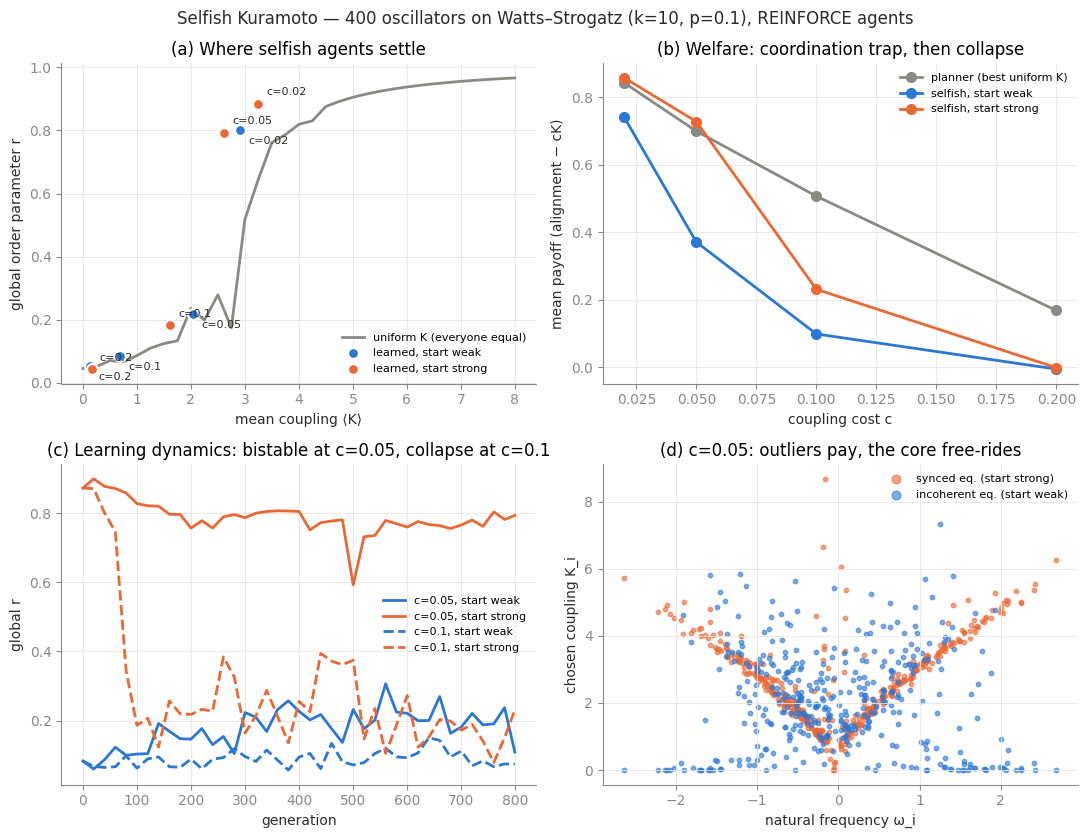

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(11, 8.5))
a = ax[0, 0]
a.plot(up[:, 0], up[:, 1], color=GRAY, lw=2, label='uniform K (everyone equal)')

for m, col, lab in [(1.0, LOW, 'learned, start weak'), (5.0, HIGH, 'learned, start strong')]:
    xs = [get(c, m)['mu'].mean() for c in costs]; ys = [get(c, m)['r'] for c in costs]
    a.scatter(xs, ys, s=60, color=col, edgecolor='white', lw=1.5, zorder=3, label=lab)
    for c, x, y in zip(costs, xs, ys):
        a.annotate(f'c={c}', (x, y), xytext=(6, -10 if m == 1 else 6), textcoords='offset points', fontsize=8, color=INK)
a.set(xlabel='mean coupling ⟨K⟩', ylabel='global order parameter r', title='(a) Where selfish agents settle')
a.legend(frameon=False, fontsize=8, loc='lower right')
b = ax[0, 1]
dn = np.mean([h[1] for h in hyst], 0)
planner = [max(np.max(up[:, 2] - c * up[:, 0]), np.max(dn[:, 2] - c * dn[:, 0])) for c in costs]
b.plot(costs, planner, color=GRAY, lw=2, marker='o', ms=7, label='planner (best uniform K)')
for m, col, lab in [(1.0, LOW, 'selfish, start weak'), (5.0, HIGH, 'selfish, start strong')]:
    b.plot(costs, [get(c, m)['welfare'] for c in costs], color=col, lw=2, marker='o', ms=7, label=lab)
b.set(xlabel='coupling cost c', ylabel='mean payoff (alignment − cK)', title='(b) Welfare: coordination trap, then collapse')
b.legend(frameon=False, fontsize=8)

cax = ax[1, 0]
for c, ls in [(0.05, '-'), (0.1, '--')]:
    for m, col in [(1.0, LOW), (5.0, HIGH)]:
        h = get(c, m)['hist']
        cax.plot(h[:, 0], h[:, 3], color=col, lw=2, ls=ls, label=f'c={c}, start {"weak" if m == 1 else "strong"}')
cax.set(xlabel='generation', ylabel='global r', title='(c) Learning dynamics: bistable at c=0.05, collapse at c=0.1')
cax.legend(frameon=False, fontsize=8)

dax = ax[1, 1]
for m, col, lab in [(5.0, HIGH, 'synced eq. (start strong)'), (1.0, LOW, 'incoherent eq. (start weak)')]:
    r = get(0.05, m)
    dax.scatter(r['omega'], r['mu'], s=10, color=col, alpha=0.6, label=lab)
dax.set(xlabel='natural frequency ω_i', ylabel='chosen coupling K_i', title='(d) c=0.05: outliers pay, the core free-rides')
dax.legend(frameon=False, fontsize=8, markerscale=2)

fig.suptitle('Selfish Kuramoto — 400 oscillators on Watts–Strogatz (k=10, p=0.1), REINFORCE agents', fontsize=12, color=INK)
fig.tight_layout()
fig.savefig('selfish_kuramoto_v0.png', dpi=150)

In [ ]:
'''

for (a)
SOlid grey line is the baseline where all the agents share a uniform K, showing sharp
synchronization transition around k = 3.
At low cost: the learned points sit above and to the left of gray line achieving high
synchroniztion with lowe average coupling than the uniform baseline.

for (b)
Compares three curves with circular markers: a grey social planner curver(uniform K) an
organe curve('selfish, start strong) and a blue curve("selfish, stat weak)
By start strong we mean having high $\mu$, so more

At c=0.02 and c=0.05 the strong-start selfish agents slightly overperforms the uniform
planner whereas weak-start agents fall into a lower-welfare coordination trap at c=0.05

for (c) tracks global synchronization r over learning parameters
At c=0.05 the system is bistable-the solid orange line maintins high sync around r=0.8
while hte solid blue line remains incogerent near r=0.1-0.3.

for (d)
Compares the synced equilibrium from a strong start(orange dots) against the inchoherent
equilirium from a weak start.


'''